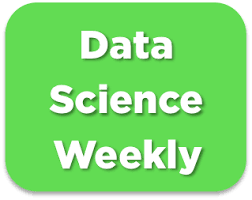

# Challenge : predict conversions 🏆🏆

This is the template that shows the different steps of the challenge. In this notebook, all the training/predictions steps are implemented for a very basic model (logistic regression with only one variable). Please use this template and feel free to change the preprocessing/training steps to get the model with the best f1-score ! May the force be with you 🧨🧨  

**For a detailed description of this project, please refer to *02-Conversion_rate_challenge.ipynb*.**

# Import libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# setting Jedha color palette as default
"""pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"
pio.renderers.default = "svg" # to be replaced by "iframe" if working on JULIE"""
# Définition d'un template personnalisé avec une palette de couleurs spécifique
custom_colorway = ["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]

custom_template = go.layout.Template(layout_colorway=custom_colorway)

from IPython.display import display

# Read file with labels

In [2]:
data = pd.read_csv('conversion_data_train.csv')
print('Set with labels (our train+test) :', data.shape)

Set with labels (our train+test) : (284580, 6)


In [38]:
data_without_labels = pd.read_csv('conversion_data_test.csv')
data_without_labels.shape

(31620, 5)

In [4]:
data.head(20)

,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0
5,US,29,0,Seo,7,0
6,US,30,1,Direct,4,0
7,UK,38,1,Ads,2,0
8,UK,26,1,Seo,4,0
9,UK,31,0,Seo,5,0


# Explore dataset

In [5]:
data_without_labels.describe(include='all')

,country,age,new_user,source,total_pages_visited
count,31620,31620.000000,31620.000000,31620,31620.000000
unique,4,NaN,NaN,3,NaN
top,US,NaN,NaN,Seo,NaN
freq,17968,NaN,NaN,15563,NaN
mean,NaN,30.620746,0.685579,NaN,4.870398
std,NaN,8.316736,0.464292,NaN,3.333128
min,NaN,17.000000,0.000000,NaN,1.000000
25%,NaN,24.000000,0.000000,NaN,2.000000
50%,NaN,30.000000,1.000000,NaN,4.000000
75%,NaN,36.000000,1.000000,NaN,7.000000


In [6]:
data.describe(include='all')

,country,age,new_user,source,total_pages_visited,converted
count,284580,284580.000000,284580.000000,284580,284580.000000,284580.000000
unique,4,NaN,NaN,3,NaN,NaN
top,US,NaN,NaN,Seo,NaN,NaN
freq,160124,NaN,NaN,139477,NaN,NaN
mean,NaN,30.564203,0.685452,NaN,4.873252,0.032258
std,NaN,8.266789,0.464336,NaN,3.341995,0.176685
min,NaN,17.000000,0.000000,NaN,1.000000,0.000000
25%,NaN,24.000000,0.000000,NaN,2.000000,0.000000
50%,NaN,30.000000,1.000000,NaN,4.000000,0.000000
75%,NaN,36.000000,1.000000,NaN,7.000000,0.000000


In [7]:
data_without_labels[data_without_labels.age>70]
data_without_labels[data_without_labels.total_pages_visited>25]

,country,age,new_user,source,total_pages_visited
21577,US,23,1,Ads,26
22806,US,20,1,Seo,26


In [8]:
# outliers : age 123 ; total pages visited 29 avg 4.87 ; 3qt=7 3sigma = 14? 
data [data.age >70 ]    # 2 outliers age >100 y w/ conversion ; 2 louches source direct age>75 


,country,age,new_user,source,total_pages_visited,converted
11331,UK,111,0,Ads,10,1
104541,US,72,1,Direct,4,0
175251,US,73,1,Seo,5,0
230590,US,79,1,Direct,1,0
233196,Germany,123,0,Seo,15,1
268311,US,77,0,Direct,4,0


In [9]:
data[data.total_pages_visited>25]  #looks good

,country,age,new_user,source,total_pages_visited,converted
9390,Germany,24,0,Seo,26,1
36590,China,22,0,Direct,26,1
58515,US,37,1,Ads,26,1
68329,US,22,0,Ads,27,1
76137,UK,17,1,Seo,27,1
80293,US,25,0,Ads,26,1
84783,Germany,22,1,Seo,27,1
87376,US,29,0,Ads,26,1
88265,US,24,0,Seo,27,1
89111,UK,19,0,Seo,26,1


In [10]:
25/284580

8.78487595755148e-05

In [11]:
# remove outliers : 
data = data [data.age <=70 ] # suppr 6 
data = data[data.total_pages_visited<=25]   # 25 

In [12]:
# The dataset is quite big : you must create a sample of the dataset before making any visualizations !
data_sample = data.sample(10000)

In [13]:
features_list = ['country', 'age','new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]
num_features = [features_list[i] for i in numeric_indices]
cat_features = [features_list[i] for i in categorical_indices]


In [14]:
# cov matrix : 
df = data.copy()
df_encoded = pd.get_dummies(df, columns=['country', 'source'], drop_first=True)
corr_matrix = df_encoded.corr()
import seaborn as sns

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title("Correlation matrix of features with 'converted'")
plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
corr_with_target = corr_matrix['converted'].sort_values(ascending=False)
print(corr_with_target)

converted              1.000000
total_pages_visited    0.527720
country_UK             0.048669
country_US             0.036297
country_Germany        0.035220
source_Seo             0.003540
source_Direct         -0.013798
age                   -0.088524
new_user              -0.151908
Name: converted, dtype: float64


In [ ]:
for i in range(len(num_features)):
    fig = px.histogram(data_without_labels, x=[num_features[i]],
                       #color='converted',
                       title=f"feature :{num_features[i]}",
                       histnorm='probability',opacity=0.5)
    fig.show()

In [ ]:

for i in range(len(num_features)):
    fig = px.histogram(data, x=[num_features[i]],
                       color='converted',
                       title=f"feature :{num_features[i]}",
                       histnorm='probability',opacity=0.5)
    fig.show()

In [ ]:
color_palette = [
    "#1f77b4",  # bleu
    "#ff7f0e",  # orange
    "#2ca02c",  # vert
    "#d62728",  # rouge
    "#9467bd",  # violet
    "#8c564b",  # marron
    "#e377c2",  # rose
    "#7f7f7f",  # gris
    "#bcbd22",  # jaune-vert
    "#17becf"   # turquoise
]
#color_palette = px.colors.qualitative.Set2 
for num in num_features:
    for cat in cat_features:
        fig = px.histogram(
            data_frame=data,
            x=num,
            color=cat,                 # 1 couleur par modalité de la variable catégorielle
            facet_row="converted",     # 2 subplots: converted=0 et converted=1
            histnorm="probability",
            barmode="overlay",
            opacity=0.5,
            nbins=30,
            title=f"{num} | couleur={cat} | facettes=converted",
            color_discrete_sequence=color_palette
        )
        fig.update_layout(
            legend_title_text=cat,
            bargap=0.05,
            margin=dict(l=40, r=20, t=70, b=40)
        )
        fig.update_xaxes(matches=None)  # garde l'auto-range par subplot si distributions très différentes
        fig.show()

In [ ]:
# tracer test / total pages /country = china / converted 

In [ ]:
sub = data[(data.total_pages_visited.isin([12,13,14])) & (data.country == 'China')]
display(sub.describe(include='all'))
sub.sample(25)

,country,age,new_user,source,total_pages_visited,converted
count,1120,1120.000000,1120.000000,1120,1120.000000,1120.000000
unique,1,NaN,NaN,3,NaN,NaN
top,China,NaN,NaN,Seo,NaN,NaN
freq,1120,NaN,NaN,535,NaN,NaN
mean,NaN,30.726786,0.684821,NaN,12.594643,0.033929
std,NaN,8.167504,0.464794,NaN,0.729787,0.181126
min,NaN,17.000000,0.000000,NaN,12.000000,0.000000
25%,NaN,25.000000,0.000000,NaN,12.000000,0.000000
50%,NaN,30.000000,1.000000,NaN,12.000000,0.000000
75%,NaN,36.000000,1.000000,NaN,13.000000,0.000000


,country,age,new_user,source,total_pages_visited,converted
271219,China,31,0,Ads,14,0
54172,China,17,1,Direct,14,0
29375,China,28,1,Seo,12,0
200002,China,31,1,Ads,12,0
22582,China,17,1,Seo,13,0
146838,China,36,1,Seo,12,0
18964,China,21,1,Ads,12,0
222394,China,32,1,Direct,12,0
65810,China,30,0,Seo,13,0
53557,China,44,0,Seo,12,0


In [ ]:
num_features

['age', 'total_pages_visited']

In [ ]:
# tracer sub / total pages /country = china / converted 
sub2 = data[(data.country=='China')& (data.converted==1)]
sub3 = data[ (data.converted==1)]
num = 'total_pages_visited'
cat = 'age'
facet = 'country'
# fig2 = px.figure(width=900,     # largeur en pixels
#     height=1200)
fig2 = px.histogram(
    data_frame=sub3,
    x=num,
    color = cat,
    facet_row=facet,
    histnorm="probability",
    barmode="stack",
    opacity=0.5,
    nbins=30,
    title=f"{num} | couleur={cat} | facettes={facet}",
    color_discrete_sequence=color_palette,
    width=900,     # largeur en pixels
    height=700
)
fig2.show()


#num_features_sub = [total_pages_]
for num in num_features:
    for cat in cat_features:
        fig = px.histogram(
            data_frame=sub,
            x=num,
            color=cat,                 # 1 couleur par modalité de la variable catégorielle
            facet_row="converted",     # 2 subplots: converted=0 et converted=1
            histnorm="probability",
            barmode="overlay",
            opacity=0.5,
            nbins=30,
            title=f"{num} | couleur={cat} | facettes=converted",
            color_discrete_sequence=color_palette
        )
        fig.update_layout(
            legend_title_text=cat,
            bargap=0.05,
            margin=dict(l=40, r=20, t=70, b=40)
        )
        fig.update_xaxes(matches=None)  # garde l'auto-range par subplot si distributions très différentes
        fig.show()

In [25]:
categorical_indices = [0,2,3]
cat_features = [features_list[i] for i in categorical_indices]
for i in range(len(cat_features)):
    fig = px.histogram(data, x=[cat_features[i]],
                       color=data['converted'].astype(str),
                       barmode = 'group',
                       title=f"feature : {cat_features[i]}",
                 histnorm='probability density',
                 opacity=0.5)
    fig.show()
    
    # conversion rate in china is highly different from UK, US & Ger 
    # a special solution to take it into account into model or data "shaping" would be fine !!  

In [36]:
categorical_indices = [0,2,3]
cat_features = [features_list[i] for i in categorical_indices]
for feature in cat_features:
    proportions = (
        pd.crosstab(
            data[feature].astype(str),
            data["converted"].astype(str),
            normalize="index",
        )
        .reindex(columns=["0", "1"], fill_value=0)
        .mul(100)
        .rename_axis(feature)
        .reset_index()
        .melt(
            id_vars=feature,
            var_name="converted",
            value_name="percentage",
        )
    )

    fig = px.bar(proportions, x=feature,
                 y='percentage',
                       color='converted',
                       barmode = 'stack',
                       title=f"repartition de converted par {feature}",
                       labels={feature:feature,'percentage': 'Pourcentage', 'converted': 'Conversion'},
                       category_orders = {"converted": ["0", "1"]},
                       width = 500,  
    )
    fig.update_traces(
        texttemplate="%{y:.1f}%",
        textposition="outside",
        textfont=dict(size=16),
        selector={"name": "1"},
    )
    fig.update_yaxes(range=[0, 110], ticksuffix="%")
    fig.show()

<Figure size 640x480 with 0 Axes>

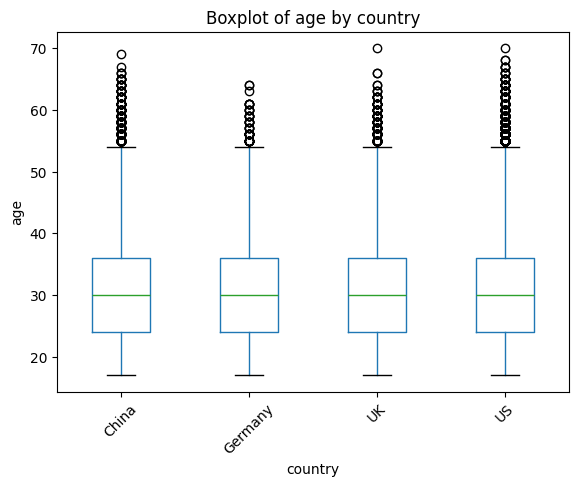

<Figure size 640x480 with 0 Axes>

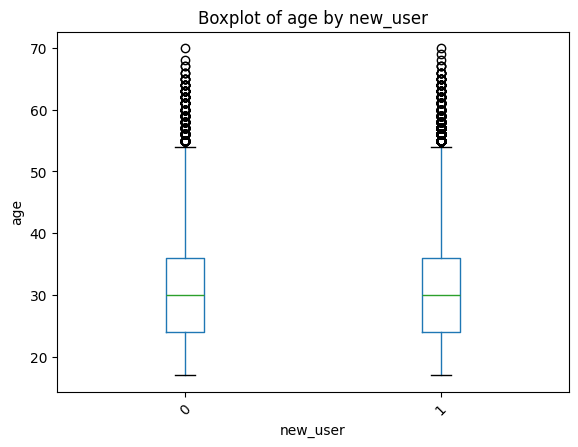

<Figure size 640x480 with 0 Axes>

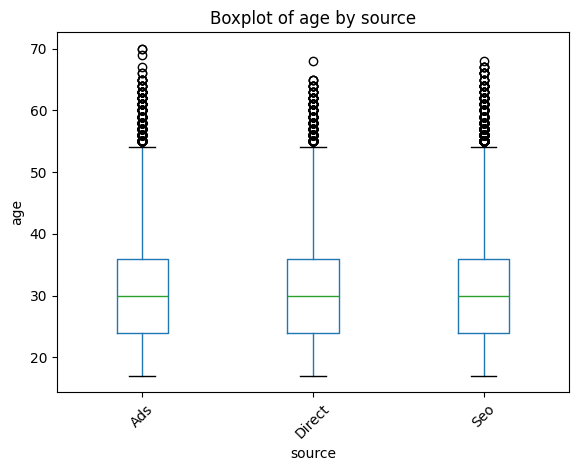

<Figure size 640x480 with 0 Axes>

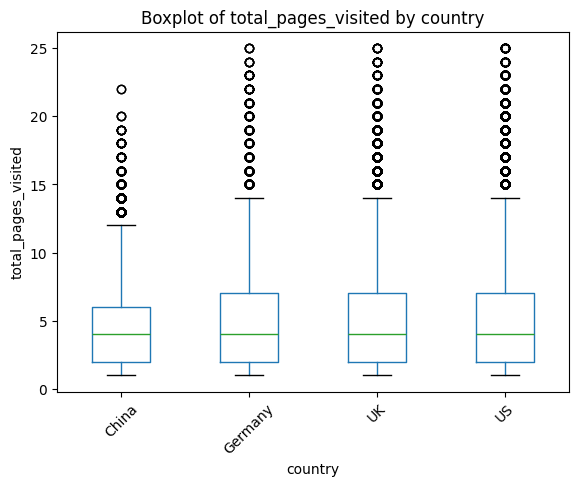

<Figure size 640x480 with 0 Axes>

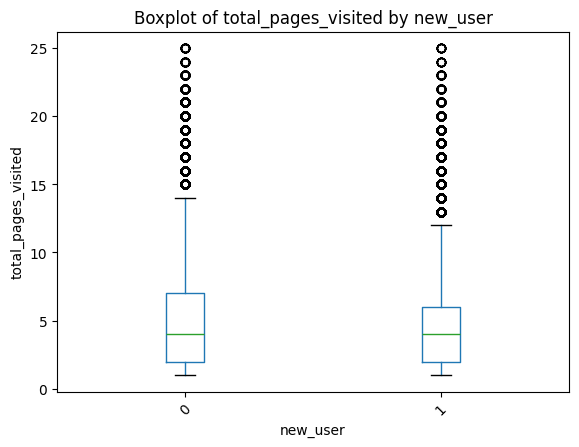

<Figure size 640x480 with 0 Axes>

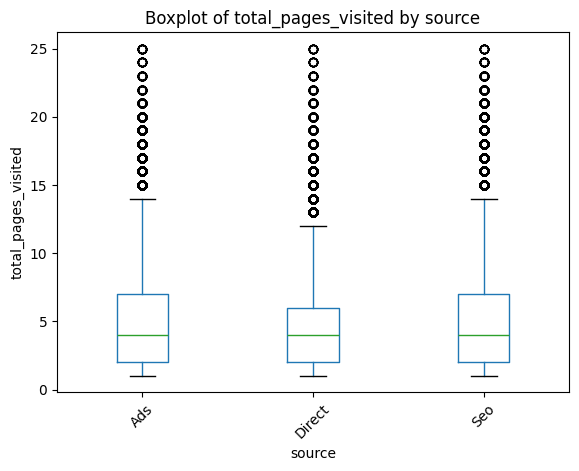

In [ ]:
for i in numeric_indices:
    for j in categorical_indices:
        plt.figure()
        data.boxplot(column=features_list[i], by=features_list[j], grid=False)
        plt.title(f'Boxplot of {features_list[i]} by {features_list[j]}')
        plt.suptitle('')
        plt.xlabel(features_list[j])
        plt.ylabel(features_list[i])
        plt.xticks(rotation=45)
        plt.show()

## synthesis EDA : 
* 5 features & 1 target label (converted)

* Clean data from outliers : 
  * age > 75

Age and pages_visited look to have an impact on conversion  
China repartition curve looks different from other countries  
source looks to have a small influence  

* main impacting feature is **total_pages_visited**
Then **age** and **new_user**
Slight impact from **country** (especially China) and **source**


# Make your model

## Choose variables to use in the model, and create train and test sets
**From the EDA, we know that the most useful feature is total_pages_visited. Let's create a baseline model by using at first only this feature : in the next cells, we'll make preprocessings and train a simple (univariate) logistic regression.**

In [ ]:
data.columns

Index(['country', 'age', 'new_user', 'source', 'total_pages_visited',
       'converted'],
      dtype='object')

In [ ]:
"""
# scenar 0 : basic
features_list = ['total_pages_visited']
numeric_indices = [0]
categorical_indices = []
"""
# scenar 1
"""features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]"""

# scen 2 : remove 'age'
"""features_list = ['country', 'new_user', 'source','total_pages_visited']
numeric_indices = [3]
categorical_indices = [0,1,2]"""

# scen 3 : ttes col + logistic + gridsearch 
"""features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]
"""
# scen 4 to 6 : arbre random forest :
# features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
# numeric_indices = [1,4]
# categorical_indices = [0,2,3]
 
 
# scen 7&8 : arbre random forest : et red features 
# features_list = ['age', 'new_user', 'total_pages_visited']
# numeric_indices = [0,2]
# categorical_indices = [1]

# scen 9 : arbre random forest :
features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]  

# scen 12 : feature eng + cat_encoder 
# des nouivelles colonnes 

# scen 13 : XGBoost 
#features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
target_variable = 'converted'

In [ ]:
X0 = data.loc[:, features_list]
Y0 = data.loc[:, target_variable]

print('Explanatory variables : ', X0.columns)
print()

Explanatory variables :  Index(['country', 'age', 'new_user', 'source', 'total_pages_visited'], dtype='object')



In [ ]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
X_train0, X_test0, Y_train0, Y_test0 = train_test_split(X0, Y0, test_size=0.1, random_state=0,stratify=Y0)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



## Training pipeline

In [ ]:
# feature_engineer ; 
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class FeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, keep_features=None, verbose=False):
        self.keep_features = keep_features
        self.verbose = verbose

        self.conv_country_ = None
        self.conv_source_ = None
        self.conv_country_source_ = None
        self.age_bins_ = None
        self.pages_bins_ = None

    def fit(self, X, y=None):
        Xy = X.copy()
        Xy['converted'] = y

        Xy['country_source'] = Xy['country'] + "_" + Xy['source']

        self.conv_country_ = Xy.groupby('country')['converted'].mean()
        self.conv_source_ = Xy.groupby('source')['converted'].mean()
        self.conv_country_source_ = Xy.groupby('country_source')['converted'].mean()

        self.age_bins_ = np.quantile(Xy['age'], [0.25, 0.5, 0.75])
        self.pages_bins_ = np.quantile(Xy['total_pages_visited'], [0.25, 0.5, 0.75])

        return self

    def transform(self, X):
        X = X.copy()

        # --- Feature engineering ---
        X['age_x_pages'] = X['age'] * X['total_pages_visited']
        X['age_div_pages'] = X['age'] / (X['total_pages_visited'] + 1)
        X['log_pages'] = np.log1p(X['total_pages_visited'])
        X['age_sq'] = X['age'] ** 2
        X['pages_sq'] = X['total_pages_visited'] ** 2
        X['pages_div_age'] = X['total_pages_visited']/X['age']

        X['age_bin'] = np.digitize(X['age'], self.age_bins_)
        X['pages_bin'] = np.digitize(X['total_pages_visited'], self.pages_bins_)

        X['country_source'] = X['country'] + "_" + X['source']

        X['country_conv'] = X['country'].map(self.conv_country_).fillna(self.conv_country_.mean())
        X['source_conv'] = X['source'].map(self.conv_source_).fillna(self.conv_source_.mean())
        X['country_source_conv'] = X['country_source'].map(self.conv_country_source_).fillna(
            self.conv_country_source_.mean()
        )
        X['new_user_x_pages'] = (1+X['new_user'])* X['total_pages_visited']
        X['new_user_x_pages_sq'] = (1+X['new_user'])* X['total_pages_visited']**2

        # --- Nettoyage des features non pertinentes ---
        if self.keep_features is not None:
            kept = []
            removed = []

            for col in X.columns:
                orig = self._map_to_original_feature(col)

                if orig in self.keep_features:
                    kept.append(col)
                else:
                    removed.append((col, orig))

            if self.verbose:
                print("\n=== Feature Engineering: Logging ===")
                print("Features d'origine conservées :", self.keep_features)
                print("\nColonnes conservées :")
                for c in kept:
                    print(f"  ✔ {c}")

                print("\nColonnes supprimées :")
                for c, orig in removed:
                    print(f"  ✘ {c}  (mapped to '{orig}')")

                print("====================================\n")

            X = X[kept]

        return X

    # --- Fonction interne : mapping vers la feature d'origine ---
    def _map_to_original_feature(self, col):
        name = col

        # 1) interactions avec pages
        if "pages" in name:
            if name.startswith("age_"):
                return "age"
            return "total_pages_visited"

        # 2) new_user_*
        if name.startswith("new_user_"):
            return "new_user"

        # 3) country_*
        if name.startswith("country_"):
            return "country"

        # 4) source_*
        if name.startswith("source_"):
            return "source"

        # 5) bins d'âge
        if name.startswith("age_bin"):
            return "age"

        # 6) cas simple
        return name


In [ ]:
# build_preprocessor & build_initial_preprocessor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(selected_features):
    """
    Construit un ColumnTransformer robuste, compatible avec une sélection
    dynamique de features d'origine.
    """

    # Toutes les features d'origine possibles
    numeric_candidates = ['age', 'total_pages_visited']
    categorical_candidates = ['country', 'new_user', 'source']

    # On garde seulement celles encore présentes
    numeric_features = [f for f in numeric_candidates if f in selected_features]
    categorical_features = [f for f in categorical_candidates if f in selected_features]

    print("=== Preprocessor dynamique ===")
    print("Numeric features utilisées :", numeric_features)
    print("Categorical features utilisées :", categorical_features)
    print("================================")

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ],
        remainder='drop'
    )

    return preprocessor



def build_initial_preprocessor(df, features_list):
    """
    Construit un preprocessor initial dynamique basé sur les features d'origine.
    Supporte la suppression future de certaines features (ex: age).
    """

    # 1) détecter num / cat automatiquement
    num_features = []
    cat_features = []

    for col in features_list:
        if col in df.columns:
            if pd.api.types.is_numeric_dtype(df[col]):
                num_features.append(col)
            else:
                cat_features.append(col)

    # 2) features FE possibles
    num_fe = [
        'age_x_pages', 'age_div_pages', 'log_pages',
        'age_sq', 'pages_sq'
    ]

    cat_fe = [
        'age_bin', 'pages_bin', 'country_source'
    ]

    extra_fe = [
        'country_conv', 'source_conv', 'country_source_conv'
    ]

    # 3) ne garder que celles qui existent réellement
    num_cols = [c for c in num_features + num_fe if c in df.columns]
    cat_cols = [c for c in cat_features + cat_fe if c in df.columns]
    extra_cols = [c for c in extra_fe if c in df.columns]

    print("=== Preprocessor initial dynamique ===")
    print("num_cols :", num_cols)
    print("cat_cols :", cat_cols)
    print("extra_cols :", extra_cols)
    print("======================================")

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
            ('extra', 'passthrough', extra_cols)
        ],
        remainder='drop'
    )

    return preprocessor


In [ ]:
# handling Scen<12
# ************************
scen=16

# Put here all the preprocessings
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np
if scen<12:
    # w/o feature engineering
    print("Encoding categorical features and standardizing numerical features...")

    featureencoder = StandardScaler()
    cat_encoder = OneHotEncoder()

    numeric_transformer = Pipeline(steps=[
        ('scaler', StandardScaler()) # pour normaliser les variables
    ])

    # Création du pipeline pour les variables catégorielles
    #categorical_features = [0] # Positions des colonnes catégorielles dans X
    categorical_transformer = Pipeline(steps=[
        ('encoder', OneHotEncoder(drop='if_binary', sparse_output=False))
    ])


    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_indices),
            ('cat', categorical_transformer, categorical_indices)
        ],
        remainder='passthrough')


    # scen 0 : 
    # X_train = featureencoder.fit_transform(X_train)

    # Apply StandardScaler to X
    X_train = preprocessor.fit_transform(X_train0)
    Y_train = Y_train0
    print(f"Preprocessing Scen{scen} ...Done")
    print(X_train[0:5,:])

else:
    # preprocessor sklearn : 
    # w/ feat eng 

    """num_cols = [
        'age', 'total_pages_visited',
        'age_x_pages', 'age_div_pages', 'log_pages',
        'age_sq', 'pages_sq'
    ]

    cat_cols = [
        'country', 'new_user', 'source',
        'age_bin', 'pages_bin', 'country_source'
    ]

    extra_cols = [
        'country_conv', 'source_conv', 'country_source_conv'
    ]"""



    # features d'origine
    #features_list = ['country', 'age', 'new_user', 'source', 'total_pages_visited']

    features_list = ['country', 'new_user','total_pages_visited','age']

    # détection automatique
    def detect_feature_types(df, features_list):
        num_features = []
        cat_features = []

        for col in features_list:
            if pd.api.types.is_numeric_dtype(df[col]):
                num_features.append(col)
            else:
                cat_features.append(col)

        return num_features, cat_features

    num_features, cat_features = detect_feature_types(X_train0, features_list)

    print("num_features :", num_features)
    print("cat_features :", cat_features)


    preprocessor = build_initial_preprocessor(X_train0, features_list)

    




num_features : ['new_user', 'total_pages_visited', 'age']
cat_features : ['country']
=== Preprocessor initial dynamique ===
num_cols : ['new_user', 'total_pages_visited', 'age']
cat_cols : ['country']
extra_cols : []


In [ ]:
# Functions run_model
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# new pipeline : FeatureEngineer → Preprocessor → Classifier
def run_model(name, model, param_grid, X_train, y_train, X_test, y_test):
    
    pipe = Pipeline(steps=[
        ('fe', FeatureEngineer()),
        ('prep', preprocessor),
        ('clf', model)
    ])
    
    
    grid = GridSearchCV(
        pipe,
        param_grid=param_grid,
        cv=3,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    # --- F1 train/test standard ---
    y_pred_train = grid.predict(X_train)
    y_pred_test = grid.predict(X_test)

    f1_train = f1_score(y_train, y_pred_train)
    f1_test = f1_score(y_test, y_pred_test)

    # --- F1 optimal (seuil optimisé) ---
    proba_test = grid.predict_proba(X_test)[:, 1]
    thresholds = np.linspace(0.1, 0.9, 50)
    f1_scores = [f1_score(y_test, proba_test > t) for t in thresholds]

    best_threshold = thresholds[np.argmax(f1_scores)]
    best_f1_opt = max(f1_scores)

    # --- Feature importances (si dispo) ---
    feature_importances = None
    try:
        #feature_importances = grid.best_estimator_.named_steps['clf'].feature_importances_
        df_feature_importances = extract_feature_importances(grid.best_estimator_, X_train)

    except:
        pass  # LogisticRegression / AdaBoost base estimator n'ont pas feature_importances

    # --- Sauvegarde du modèle entraîné ---
    trained_model = grid.best_estimator_

    return {
        "model": name,
        "best_params": grid.best_params_,
        "f1_train": f1_train,
        "f1_test": f1_test,
        "best_threshold": best_threshold,
        "f1_test_opt": best_f1_opt,
        "feature_importances": df_feature_importances,
        "trained_model": trained_model
    }

def extract_feature_importances(best_estimator, X_train):
    """
    Retourne un DataFrame propre :
    feature_name | importance
    Compatible avec XGBoost, RF, LogisticRegression, etc.
    appele par run_model
    """

    import numpy as np
    import pandas as pd

    # 1. Récupérer les étapes du pipeline
    prep = best_estimator.named_steps["prep"]
    clf = best_estimator.named_steps["clf"]

    # 2. Récupérer les noms de features après preprocessing
    try:
        feature_names = prep.get_feature_names_out()
    except:
        feature_names = X_train.columns

    # 3. Récupérer les importances selon le modèle
    if hasattr(clf, "feature_importances_"):
        importances = clf.feature_importances_

    elif hasattr(clf, "coef_"):
        importances = np.abs(clf.coef_).flatten()

    else:
        return pd.DataFrame(columns=["feature", "importance"])

    # 4. Construire le DataFrame propre
    df_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False)

    return df_imp


# get and select features importances :
# best_model.named_steps["clf"]
def get_feature_importances(model, X_sample):
    """
    model : pipeline complet (FE + preprocess + clf)
    X_sample : DataFrame brut (pour récupérer les noms des features après preprocess)
    """
    # 1) Récupérer le preprocess transformé pour connaître les noms des features
    fe = model.named_steps['fe']
    prep = model.named_steps['prep']
    clf = model.named_steps['clf']

    # Appliquer FE sur un échantillon
    X_fe = fe.transform(X_sample.copy())

    # Récupérer les noms après preprocessing
    feature_names = prep.get_feature_names_out()

    # 2) Récupérer les importances selon le modèle
    if hasattr(clf, "feature_importances_"):
        importances = clf.feature_importances_

    elif hasattr(clf, "get_feature_importance"):
        importances = clf.get_feature_importance()

    else:
        print("⚠ Ce modèle ne fournit pas d'importances de features.")
        return None

    # 3) Construire un DataFrame propre
    df_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False)

    return df_imp

def select_top_features(df_imp, cumulative_threshold=0.95):
    df_imp["cum_importance"] = df_imp["importance"].cumsum()
    selected = df_imp[df_imp["cum_importance"] <= cumulative_threshold]["feature"].tolist()
    return selected


def aggregate_importances_by_original_feature(df_imp):
    """
    Agrège les importances par feature d'origine en conservant les noms complets.
    Exemple :
      num__total_pages_visited_log  -> total_pages_visited
      cat__new_user                 -> new_user
      extra__country_conv           -> country
    """

    def clean_name(x):
        # 1) enlever le préfixe du ColumnTransformer
        name = x.split("__")[-1]

        # 2) enlever les suffixes de feature engineering
        for suffix in ["_log", "_sq", "_bin", "_conv", "_scaled"]:
            if name.endswith(suffix):
                name = name[: -len(suffix)]
        
        return name

    df_imp["orig_feature"] = df_imp["feature"].apply(clean_name)

    return df_imp.groupby("orig_feature")["importance"].sum().sort_values(ascending=False)


import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

def plot_roc_pr(model, X_test, y_test, model_name="Model"):
    # Probabilités
    y_proba = model.predict_proba(X_test)[:, 1]

    # --- ROC ---
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    # --- Precision-Recall ---
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)

    # --- Plot ---
    plt.figure(figsize=(14, 6))

    # ROC
    plt.subplot(1, 2, 1)
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {model_name}")
    plt.legend()

    # PR
    plt.subplot(1, 2, 2)
    plt.plot(recall, precision, label=f"AP = {pr_auc:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision–Recall Curve — {model_name}")
    plt.legend()

    plt.tight_layout()
    plt.show()

def aggregate_importances_by_original_feature(df_imp):
    """
    Regroupe les importances par feature d'origine.
    Fonction adaptée à TON dataset réel.
    """

    def clean_name(x):
        # 1) Enlever le préfixe du ColumnTransformer
        name = x.split("__")[-1]

        # 2) Enlever les suffixes de feature engineering
        suffixes = ["_log", "_sq", "_bin", "_conv", "_scaled"]
        for suffix in suffixes:
            if name.endswith(suffix):
                name = name[: -len(suffix)]

        # 3) Interactions avec pages -> total_pages_visited
        if "pages" in name:
            if name.startswith("age_"):
                return "age"
            return "total_pages_visited"

        # 4) One-hot encodings new_user_*
        if name.startswith("new_user_"):
            return "new_user"

        # 5) One-hot encodings simples
        base = name.split("_")[0]
        if base in ["country", "source"]:
            return base

        # 6) Colonnes multi-niveaux country_source_*
        if name.startswith("country_source"):
            return "country"

        # 7) Bins d'âge -> age
        if name.startswith("age_bin"):
            return "age"

        return name

    df_imp["orig_feature"] = df_imp["feature"].apply(clean_name)

    return df_imp.groupby("orig_feature")["importance"].sum().sort_values(ascending=False)


In [ ]:
# ** run model for Scen <12
if scen<12:
    # Train model
    print("Train model...")
    #classifier = LogisticRegression(penalty='l2',solver = 'lbfgs',max_iter=1000) # 
    #classifier = LogisticRegression() # 

    #classifier.fit(X_train, Y_train)

    # Définition du modèle de base
    log_reg = LogisticRegression(max_iter=1000)
    param_grid = {
        'penalty': ['l1', 'l2'],          # types de régularisation à tester
        'solver': ['liblinear', 'saga'],  # solveurs compatibles avec l1 et l2
        'C': [0.01, 0.1, 1, 10, 100]     # inverse de la force de régularisation
    }
    # Scen 6 & 6b :
    # rdf = RandomForestClassifier()
    # # Définition de la grille des hyperparamètres à tester
    # {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 64, 'n_estimators': 30}
    # params_rdf = {
    #     "max_depth": [7,10,15],
    #     "min_samples_leaf": [1, 2, 5],
    #     "min_samples_split": [16,32,64],
    #     "n_estimators": [15,20,30],
    #     'criterion':['gini','entropy']
    # }
    # grid_search = GridSearchCV(
    #     rdf, param_grid=params_rdf, cv=5,
    #     verbose=1
    # )  # cv : the number of folds to be used for CV

    # scen 3 : Création de l'objet GridSearchCV
    # grid_search = GridSearchCV(estimator=classifier,
    #                            param_grid=param_grid,
    #                            cv=5,              # validation croisée 5 folds
    #                            scoring='accuracy', # critère d'évaluation
    #                            n_jobs=-1)          # parallélisation
    # Scen 8 bagging & log reg 
    # model = BaggingClassifier(estimator=log_reg)

    # # Grid of values to be tested
    # params = {
    #     "estimator__C": [
    #         0.01,0.05,0.1,0.5,],  # base_estimator__ prefix because C is a parameter from LogisticRegression!
    #     "n_estimators": [
    #         5,10,20,30,],  # n_estimators is a hyperparameter of the ensemble method
    # }
    # grid_search = GridSearchCV(
    #     model, param_grid=params, cv=3,
    #     verbose=1
    # )  # cv : the number of folds to be used for CV


    # # scen10 : DTC + bagging
    # decision_tree = DecisionTreeClassifier()
    # model = BaggingClassifier(estimator=decision_tree)

    # # Grid of values to be tested
    # params = {
    #     "estimator__max_depth": [1, 2, 3],
    #     "estimator__min_samples_leaf": [1, 2, 3],
    #     "estimator__min_samples_split": [2, 3, 4],
    #     "n_estimators": [2, 4, 6, 8, 10],
    # } 
    # grid_search = GridSearchCV(
    #     model, param_grid=params, cv=3,
    #     verbose=1)  # cv : the number of folds to be used for CV

    # # scen 11 : adaboost + logreg:
    # Perform grid search
    print("Grid search...")
    # log_reg = LogisticRegression(
    #     max_iter=1000
    # )  # max_iter changed because of convergence warning
    model = AdaBoostClassifier(estimator=log_reg)

    # Grid of values to be tested
    params = {
        "estimator__C": [0.01,0.05,0.1,0.5,],  # base_estimator__ prefix because C is a parameter from LogisticRegression!
        "n_estimators": [5,10,20,30],  # n_estimators is a hyperparameter of the ensemble method
    }
    print(params)
    grid_search = GridSearchCV(
        model, param_grid=params, cv=3,
        verbose=1,n_jobs=-1
    )  # cv : the number of folds to be used for CV

    # Entraînement sur les données d'entraînement
    print("Lancement du GridSearchCV...")
    grid_search.fit(X_train, Y_train)
    print("...Terminé.")
    print("...Done.")
    print("Best hyperparameters : ", grid_search.best_params_)
    


In [ ]:
# compute scale_pos_weight to improve importance of class converted=1 
pos = (Y_train0 == 1).sum()
neg = (Y_train0 == 0).sum()

scale_pos_weight = neg / pos
print(scale_pos_weight)

30.086914299587278



=== Running model XGBoost ===
Fitting 3 folds for each of 9 candidates, totalling 27 fits
{'model': 'XGBoost', 'best_params': {'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 200, 'clf__subsample': 0.85}, 'f1_train': 0.7671669544428211, 'f1_test': 0.7592033796016898, 'best_threshold': np.float64(0.4102040816326531), 'f1_test_opt': 0.7683352735739232, 'feature_importances':                     feature  importance
1  num__total_pages_visited    0.650471
3        cat__country_China    0.163329
0             num__new_user    0.134850
2                  num__age    0.025033
6           cat__country_US    0.016332
5           cat__country_UK    0.006276
4      cat__country_Germany    0.003708, 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['new_user',
                          

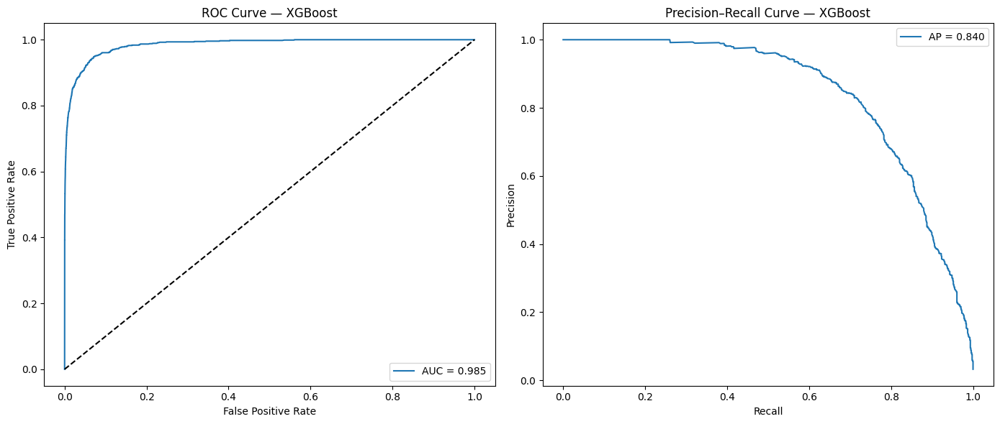

... done...


,model,best_params,f1_train,f1_test,best_threshold,f1_test_opt,feature_importances,trained_model
0,XGBoost,"{'clf__colsample_bytree': 0.85, 'clf__learning...",0.767167,0.759203,0.410204,0.768335,feature importance 1 num...,"(FeatureEngineer(), ColumnTransformer(transfor..."


In [ ]:
# 2nd part scen >=12 2nd genertation of search : 
from sklearn.ensemble import BaggingClassifier    
# 4 models to run:
# scen12 : models w/ grid lights 
"""=== Running model RandomForest ===
{'model': 'RandomForest', 
'best_params': {'clf__max_depth': None, 'clf__min_samples_leaf': 20, 'clf__min_samples_split': 50, 'clf__n_estimators': 300}, 'f1_train': 0.5598732308135557, 'f1_test': 0.5458715596330275, 'best_threshold': np.float64(0.9), 'f1_test_opt': 0.7548179871520343, 'feature_importances': array([1.13699672e-02, 1.75955481e-01, 7.06810613e-02, 1.27067321e-01,
=== Running model XGBoost ===
{'model': 'XGBoost', 
'best_params': {
    'clf__colsample_bytree': 0.85, 
    'clf__learning_rate': 0.05, 
    'clf__max_depth': 4, 
    'clf__n_estimators': 400, 
    'clf__subsample': 0.85}, 
    'f1_train': 0.7674325407427197, 'f1_test': 0.7654171704957679, 
    'best_threshold': np.float64(0.3938775510204082), 
    'f1_test_opt': 0.7671075330649799, 
    === Running model CatBoost ===
{'model': 'CatBoost', 'best_params': {'clf__depth': 6, 'clf__iterations': 800, 'clf__l2_leaf_reg': 5, 'clf__learning_rate': 0.05}, 'f1_train': 0.7784848281867506, 'f1_test': 0.7587878787878788, 'best_threshold': np.float64(0.44285714285714284), 'f1_test_opt': 0.7636579572446556, 'feature_importances': array([3.18079397e+00, 1.72247117e+01, 5.27787249e+00, 4.78884683e+00,
=== Running model AdaBoost + LogisticRegression ===
Fitting 3 folds for each of 4 candidates, totalling 12 fits
{'model': 'AdaBoost + LogisticRegression', 'best_params': {'clf__estimator__C': 0.1, 'clf__learning_rate': 1.0, 'clf__n_estimators': 20}, 'f1_train': 0.6745101900167372, 'f1_test': 0.6666666666666666, 'best_threshold': np.float64(0.5081632653061224), 'f1_test_opt': 0.6730245231607629, 'feature_importances': None, 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),
"""
# use scale pos weight  to improve taking into account class 'converted'=1 that is around 1/30 of class0
scale_pos_weight = 30 # integrated at scen16 
models_light = {
    "RandomForest": {
        "model": RandomForestClassifier(class_weight='balanced'),
        "params": {   
            "clf__criterion":['entropy','gini'],
            "clf__n_estimators": [100,300,500],
            "clf__max_depth": [10,15, None],
            "clf__min_samples_leaf": [5,20, 50],
            "clf__min_samples_split": [50, 100]
        }
    },
    "XGBoost": {
        "model": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "clf__n_estimators": [100,200,400],
            "clf__max_depth": [4, 6,8],
            "clf__learning_rate": [0.05],
            "clf__subsample": [0.85],
            "clf__colsample_bytree": [0.85]
        }
    },
    "AdaBoost + LogisticRegression": {
        "model": AdaBoostClassifier(estimator=LogisticRegression(max_iter=500)),
        "params": {
                "clf__estimator__C": [0.05, 0.1],
                "clf__n_estimators": [20, 50],
                "clf__learning_rate": [1.0]
        }
    }
}
model_catboost_light = {
    "CatBoost": {
        "model": CatBoostClassifier(verbose=False, loss_function='Logloss'),
        "params": {
            "clf__iterations": [800],
            "clf__depth": [6],
            "clf__learning_rate": [0.05],
            "clf__l2_leaf_reg": [5]
        }
    },
}
models_heavy = {
    "RandomForest": {
        "model": RandomForestClassifier(class_weight='balanced'),
        "params": {
            "clf__n_estimators": [300, 600],
            "clf__max_depth": [10,20,None],
            "clf__min_samples_leaf": [10, 20, 50, 100],
            "clf__min_samples_split": [50, 100, 200]
        }
    },

    "XGBoost": {
        "model": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "clf__n_estimators": [400, 800, 1200],
            "clf__max_depth": [4, 6, 8],
            "clf__learning_rate": [0.03, 0.05, 0.1],
            "clf__subsample": [0.7, 0.85, 1.0],
            "clf__colsample_bytree": [0.7, 0.85, 1.0],
            "clf__min_child_weight": [1, 5, 10]
        }
    },

    "CatBoost": {
        "model": CatBoostClassifier(verbose=False, loss_function='Logloss'),
        "params": {
            "clf__iterations": [600, 1000, 1500],
            "clf__depth": [4, 6, 8],
            "clf__learning_rate": [0.03, 0.05],
            "clf__l2_leaf_reg": [3, 5, 7, 9],
            "clf__bagging_temperature": [0.0, 0.5, 1.0]
        }
    },

    "AdaBoost + LogisticRegression": {
        "model": AdaBoostClassifier(estimator=LogisticRegression(max_iter=500)),
        "params": {
            "clf__estimator__C": [0.01, 0.05, 0.1, 0.5, 1.0],
            "clf__n_estimators": [20, 50, 100, 200],
            "clf__learning_rate": [0.5, 1.0, 1.5]
        }
    }
}

models_2 = {
    "stacking":{
        "model": StackingClassifier(
            estimators=[
                ('rf', RandomForestClassifier(class_weight='balanced')),
                ('gb', GradientBoostingClassifier()),
            ],
            final_estimator=LogisticRegression(max_iter=200),
            stack_method='predict_proba',
            passthrough=False
        ),
        "params": {
            # On ne grid-search que le méta-modèle pour rester léger
            "clf__final_estimator__C": [0.1, 1.0, 5.0]
        },
    },
    "Bootstrap" : {
        "model": BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            bootstrap=True,
            bootstrap_features=False,
            random_state=42
        ),
        "params": {
            "clf__n_estimators": [50, 100, 200],
            "clf__max_samples": [0.5, 0.7, 1.0],
            "clf__max_features": [0.5, 0.7, 1.0]
        }
    }
}
models_16 = {
    "XGBoost": {
        "model": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "clf__n_estimators": [100,200,400],
            "clf__max_depth": [4, 6,8,10],
            "clf__learning_rate": [0.05],
            "clf__subsample": [0.85],
            "clf__colsample_bytree": [0.85],
            #"clf__scale_pos_weight": [scale_pos_weight/1.6,scale_pos_weight,scale_pos_weight*1.6 ]  # added at scen16
        }
    }
}

# ******** Run model >scen12 *****************
# ********************************************
if scen>=12:
    # gen fonction train model + gridsearch  + F1 
    # Scen >=12     
    # run models :
    if scen==12:
        models_dico = models_light
        gen_out_suff = "sc12"
    elif 13 <= scen <= 14:
        models_dico= models_light
        #gen_out_suff = "sc13"
    elif scen==15: # alors model2
        models_dico = models_2 
    elif scen>=16:
        models_dico = models_16
        
    results = []
    saved_models = []
    for name, cfg in models_dico.items():
        print(f"\n=== Running model {name} ===")
        res = run_model(
            name=name,
            model=cfg["model"],
            param_grid=cfg["params"],
            X_train=X_train0,
            y_train=Y_train0,
            X_test=X_test0,
            y_test=Y_test0
        )
        print(res)
        results.append(res)
        saved_models.append(res["trained_model"])
        
            # --- Courbes ROC + PR ---
        plot_roc_pr(
            model=res["trained_model"],
            X_test=X_test0,
            y_test=Y_test0,
            model_name=name
        )
            
df_results = pd.DataFrame(results)

print("... done...")
display(df_results)


In [ ]:
df_imp = extract_feature_importances(best_estimator, X_train)


NotFittedError: This ColumnTransformer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
selected_features

['total_pages_visited', 'country', 'new_user']

In [ ]:
# Best_model : keep all features, retrain & export predictions for Test_set
# ******************************************************  
# scen16a : keep features, retrain on Xfull & export 
# scen16b : keep features & retrain on Xfill & recompute threshold on Xfull
#scen 17a : 17a: scale_pos_weight 18.75
# 17b : reset thr on Xfull 

gen_out_suff = 'scen16bisa' # Best model XGboost w/ all features , F1 train = 0.76.6
opt_threshold_X_full = 0

# 1) Construire X_full et Y_full
X_full = pd.concat([X_train0, X_test0], axis=0)
Y_full = pd.concat([Y_train0, Y_test0], axis=0)

# 2) Récupérer le meilleur modèle et son seuil optimal
best_idx = df_results['f1_test_opt'].idxmax()
best_model = saved_models[best_idx]
best_threshold = df_results.loc[best_idx, 'best_threshold']
print(f"threshold of best_model: {best_threshold}")

print(f"Retraining best_model on ALL labeled data: {df_results.loc[best_idx, 'model']}")

# 3) Ré‑entraîner le pipeline complet
best_model.fit(X_full, Y_full)
proba_full = best_model.predict_proba(X_full)[:, 1]
preds_full = (proba_full > best_threshold).astype(int)
f1_full = f1_score(Y_full, preds_full)
print("F1 score on X_full :", f1_full)
# *** recompute Threshold : ***
if opt_threshold_X_full:  
    proba_full = best_model.predict_proba(X_full)[:, 1]
    thresholds = np.linspace(0, 1, 200)
    f1_scores = [f1_score(Y_full, (proba_full > t).astype(int)) for t in thresholds]

    best_threshold_full = thresholds[np.argmax(f1_scores)]
    print("New best threshold on X_full:", best_threshold_full)
    preds_full = (proba_full > best_threshold_full).astype(int)
    f1_full = f1_score(Y_full, preds_full)

    print("F1 score on X_full with new threshold:", f1_full)
    best_threshold = best_threshold_full
    

# 4) Charger les données finales
data_without_labels = pd.read_csv('conversion_data_test.csv')

# IMPORTANT : ne pas réduire les colonnes !
X_without_labels = data_without_labels.copy()

# 5) Probabilités
proba_final = best_model.predict_proba(X_without_labels)[:, 1]

# 6) Appliquer le seuil optimal
preds_final = (proba_final > best_threshold).astype(int)

# 7) Sauvegarde
Y_predictions = pd.DataFrame({'converted': preds_final})
Y_predictions.to_csv(f"conversion_data_test_predictions_Cyril_Braguy{gen_out_suff}.csv", index=False)

print("Predictions saved.")



threshold of best_model: 0.4102040816326531
Retraining best_model on ALL labeled data: XGBoost
F1 score on X_full : 0.7698793093491945
Predictions saved.


In [ ]:

# get feature importances, select & retrain best model
# ******************************************************
gen_out_suff = 'scen14c'
# 1) Récupérer le meilleur modèle
best_idx = df_results['f1_test_opt'].idxmax()
print(f"best idx: {best_idx}")
best_model = saved_models[best_idx]
print(f"best model: {best_model}")


# 2) Extraire les importances
df_imp = get_feature_importances(best_model, X_train0)

# 3) Agréger par feature d'origine
df_orig = aggregate_importances_by_original_feature(df_imp)

# 4) Sélectionner les meilleures features (95% importance cumulée)
df_orig_cum = df_orig.cumsum() / df_orig.sum()
selected_features = df_orig_cum[df_orig_cum <= 0.98].index.tolist()
print("Selected features : ", selected_features)

# debug 
#print(df_imp[["feature", "orig_feature"]].head(50))

best idx: 1
best model: Pipeline(steps=[('fe', FeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['new_user',
                                                   'total_pages_visited',
                                                   'age']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['country']),
                                                 ('extra', 'passthrough',
                                                  [])])),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               cols...
                               feature_types=None, feature_weights=None,
 

In [ ]:
fe = FeatureEngineer(keep_features=selected_features, verbose=True)
_ = fe.fit(X_train0, Y_train0)
X_debug = fe.transform(X_train0)


=== Feature Engineering: Logging ===
Features d'origine conservées : ['total_pages_visited', 'country', 'new_user']

Colonnes conservées :
  ✔ country
  ✔ new_user
  ✔ total_pages_visited
  ✔ log_pages
  ✔ pages_sq
  ✔ pages_bin
  ✔ country_source
  ✔ country_conv
  ✔ country_source_conv

Colonnes supprimées :
  ✘ age  (mapped to 'age')
  ✘ source  (mapped to 'source')
  ✘ age_x_pages  (mapped to 'age')
  ✘ age_div_pages  (mapped to 'age')
  ✘ age_sq  (mapped to 'age_sq')
  ✘ age_bin  (mapped to 'age')
  ✘ source_conv  (mapped to 'source')



In [ ]:

# 6) Reconstruire un pipeline robuste sur selected_features
#    avec les mêmes hyperparamètres
# new_clf contient les selected_features
clf_class = best_model.named_steps['clf'].__class__
clf_params = best_model.named_steps['clf'].get_params()
new_clf = clf_class(**clf_params)

preprocessor2 = build_preprocessor(selected_features)

new_pipeline = Pipeline(steps=[
    ('fe', FeatureEngineer(keep_features=selected_features, verbose=False)),
    ('prep', preprocessor2),
    ('clf', new_clf),
])

# Vérification : même modèle ?
print("Ancien modèle :", best_model.named_steps['clf'].__class__.__name__)
print("Nouveau modèle :", new_pipeline.named_steps['clf'].__class__.__name__)

# 7) Ré‑entraîner sur X_train0 , Y_train0 :
new_pipeline.fit(X_train0, Y_train0)

# 8) Scores F1 sur train et test
best_threshold = df_results.loc[best_idx, 'best_threshold']
print(f"best threshold on selected features: {best_threshold} ")

proba_train = new_pipeline.predict_proba(X_train0)[:, 1]
proba_test = new_pipeline.predict_proba(X_test0)[:, 1]
print(f"proba train: {proba_train} ")
print(f"proba test: {proba_test} ")

preds_train = (proba_train > best_threshold).astype(int)
f1_train = f1_score(Y_train0, preds_train)

preds_test = (proba_test > best_threshold).astype(int)
f1_test = f1_score(Y_test0, preds_test)

print(f"F1 score X_train (reduced features) : {f1_train:.4f}")
print(f"F1 score X_test  (reduced features) : {f1_test:.4f}")



=== Preprocessor dynamique ===
Numeric features utilisées : ['total_pages_visited']
Categorical features utilisées : ['country', 'new_user']
Ancien modèle : XGBClassifier
Nouveau modèle : XGBClassifier
best threshold on selected features: 0.4102040816326531 
proba train: [3.7195645e-05 7.6954286e-03 4.5242058e-03 ... 1.7719467e-04 5.0157352e-05
 4.5242058e-03] 
proba test: [6.6670484e-04 5.1266255e-05 8.3015027e-04 ... 1.6354329e-04 3.4552880e-04
 3.0309935e-03] 
F1 score X_train (reduced features) : 0.7605
F1 score X_test  (reduced features) : 0.7493


In [ ]:
# 8.5 : re-Train model sur X_full : 
# Concatenate our train and test set to train your best classifier on all data with labels
X_full = pd.concat([X_train0, X_test0], axis=0)
Y_full = pd.concat([Y_train0, Y_test0], axis=0)

new_pipeline.fit(X_full, Y_full)


print(f"Retraining best model on ALL labeled data: {df_results.loc[best_idx, 'model']}")

best_model.fit(X_full, Y_full) 

# 9) Prédictions fichier final

data_without_labels = pd.read_csv('conversion_data_test.csv')
X_without_labels = data_without_labels.copy()

proba_final = new_pipeline.predict_proba(X_without_labels)[:, 1]
preds_final = (proba_final > best_threshold).astype(int)

Y_predictions = pd.DataFrame({'converted': preds_final})
Y_predictions.to_csv(f"conversion_data_test_predictions_Cyril_Braguy{gen_out_suff}.csv", index=False)

print("Predictions saved.")

Retraining best model on ALL labeled data: XGBoost
Predictions saved.


scen 0 : 
Scen_nr        cols        model       F1_train    F1_test 
0              nb_pages    Logistic    0.69
Confusion matrix on train set : 
[[246817   1082]  
 [  3280   4943]]  

Confusion matrix on test set : 
[[27384   117]  
 [  371   586]]  


1              all         logistic    0.76        0.757   
Confusion matrix on train set : 
[[246946    953]
 [  2558   5665]]

Confusion matrix on test set : 
[[27394   107]
 [  309   648]]

2           suppr age       logistic    0.74     
3           all             log+gridsearch  0.76497     0.756851  
4           all             rdmF + gs {'criterion': 'gini',
 'max_depth': 10,
 'min_samples_split': 8,
 'n_estimators': 20}        0.7780  0.75635
5           all             rdf+gs {'criterion': 'entropy',
 'max_depth': 10,
 'min_samples_split': 32,
 'n_estimators': 20}
                            0.7727668699323192
                f1-score on test set :  0.76096997 

6 ***       all             rdf+gs  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 64, 'n_estimators': 30}
f1-score on train set :  0.7672558639693527   ***
f1-score on test set :  0.7628985507246376

6b          all+Rm_outl   rdf+gs

7           ['age', 'new_user', 'total_pages_visited']  rdf+gs 
f1 0.74  bof 

8           idem    bagging+ logreg     0.7411  0.7426

9:          all     bagging+ logreg     {'estimator__C': 0.5, 'n_estimators': 10}
f1-score on train set :  0.7638063439065108
f1-score on test set :  0.7553324968632371 

10          all+Rm_outl DTC + bagging  {'estimator__max_depth': 3, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 3, 'n_estimators': 2}
f1-score on train set : 0.7317
f1-score on test set :  0.7352

11          all+rm outl 
adaboost w/ logistic regression 
{'estimator__C': 0.5, 'n_estimators': 5}
f1-score on train set : 0.6326
f1-score on test set :  0.6372


12.2a :     all + rmoutl ; XGBoost  'best_params': {'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 400, 'clf__subsample': 0.85}, 'f1_train': 0.7666889632107023, 'f1_test': 0.7608034083992696, 'best_threshold': np.float64(0.42653061224489797), 'f1_test_opt': 0.7692307692307693, 

12.2b : le meme en recalculant un threshold sur Xfull : 
threshold of best_model: 0.42653061224489797
Retraining best_model on ALL labeled data: XGBoost
New best threshold on X_full: 0.4170854271356784
F1 score on X_full with new threshold: 0.7722048066875653
Predictions saved.

12.2  :     all +rm oul XGBoost  le meme du dessus ; mais retrained sur les sel features [pages, country & new_user ]
 F1 score X_train (reduced features) : 0.7605
F1 score X_test  (reduced features) : 0.7501 

13 :    features [pages, country & new_user ] + rm outl + feat engineering XGBoost
c'est decevant ...  
model	best_params	f1_train	f1_test	best_threshold	f1_test_opt	feature_importances	trained_model
0	RandomForest	{'clf__criterion': 'entropy', 'clf__max_depth'...	0.477405	0.473873	0.900000	0.742917	[0.08878262306288662, 0.8192724219275447, 0.07...	(FeatureEngineer(), ColumnTransformer(transfor...
1	XGBoost	{'clf__colsample_bytree': 0.85, 'clf__learning...	0.750459	0.740420	0.328571	0.756878	[0.12744237, 0.6987239, 0.15093504, 0.00339034...	(FeatureEngineer(), ColumnTransformer(transfor...
2	AdaBoost + LogisticRegression	{'clf__estimator__C': 0.05, 'clf__learning_rat...	0.532074	0.533637	0.475510	0.533637	None	(FeatureEngineer(), ColumnTransformer(transfor...

14a : 4 best features ['country', 'new_user','total_pages_visited','age'] 
            XGBoost                          F1train :  F1_test  best thr   F1_test_opt  F1 X_full :
                                            0.767167	0.759203	0.410204	0.768335    0.7698793
14b : same w/ recompute threshold on Xfull 
        New best threshold on X_full: 0.4221105527638191
        F1 score on X_full with new threshold: 0.7704736995059576
14c : same w/ retrain model on 3 best features ?
    F1 score X_train (reduced features) : 0.7605
    F1 score X_test  (reduced features) : 0.7493

15 : 4 featuers + stacking & bootstrap 
    stacking : 'f1_train': 0.7717979158422372, 'f1_test': 0.760817307692
    F1train :  F1_test  best thr   F1_test_opt  F1 X_full :
15a    0.771798	0.760817	0.442857	0.763913	

    bootstrap : 
    F1train :  F1_test  best thr   F1_test_opt  F1 X_full :
    0.778384	0.746812	0.459184	0.757845

15a        F1train :  F1_test  best thr   F1_test_opt  F1 X_full :
15a    0.771798	0.760817	0.442857	0.763913	   0.774388
15b : thr optim on Xfull:
threshold of best_model: 0.44285714285714284
Retraining best_model on ALL labeled data: stacking
F1 score on X_full : 0.7740585774058577
New best threshold on X_full: 0.4170854271356784
F1 score on X_full with new threshold: 0.7745771517635514
Predictions saved.

16.0
16a : 4 features + rmoutl XGBoost + add feature_eng on pages*new_user 

'XGBoost', 
'best_params': 
{'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 
'clf__max_depth': 4, 
'clf__n_estimators': 200, 'clf__subsample': 0.85},

'f1_train': 0.7671669, 'f1_test': 0.75920, 
'best_threshold': 0.41), 'f1_test_opt': 0.76833
1  num__total_pages_visited    0.650471
3        cat__country_China    0.163329
0             num__new_user    0.134850
2                  num__age    0.025033
6           cat__country_US    0.016332
5           cat__country_UK    0.006276
4      cat__country_Germany    0.003708

16b : recompute threshold on X_full   : 
F1 score on X_full : 0.7698793093491945 (16a)
New best threshold on X_full: 0.4221105527638191
F1 score on X_full with new threshold: 0.7704736995059576 (16b)

----------
16 bis : re-opt model 16 w/o scale_pos_weight
------
a refaire et a exporter
model	best_params : 'XGBoost', 'best_params': 
{'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 
'clf__max_depth': 4, 'clf__n_estimators': 200, 'clf__subsample': 0.85}

f1_train	f1_test	    best_threshold	f1_test_opt	
0.767167	0.759203	0.410204	    0.768335

16bis : 
{'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4,
 'clf__n_estimators': 200, 'clf__subsample': 0.85}, 
 
 'f1_train': 0.7671669544428211, 'f1_test': 0.7592033796016898, 'best_threshold': np.float64(0.4102040816326531), 'f1_test_opt': 0.7683352735739232, 
 
 'feature_importances':                     feature  importance
1  num__total_pages_visited    0.650471
3        cat__country_China    0.163329
0             num__new_user    0.134850
2                  num__age    0.025033
6           cat__country_US    0.016332
5           cat__country_UK    0.006276
4      cat__country_Germany    0.003708

16bis reexecuted : 
'XGBoost', 'best_params': {'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 200, 'clf__subsample': 0.85}, 'f1_train': 0.7671669544428211, 'f1_test': 0.7592033796016898, 'best_threshold': np.float64(0.4102040816326531), 'f1_test_opt': 0.7683352735739232, 'feature_importances':                     feature  importance
1  num__total_pages_visited    0.650471
3        cat__country_China    0.163329
0             num__new_user    0.134850
2                  num__age    0.025033
6           cat__country_US    0.016332
5           cat__country_UK    0.006276
4      cat__country_Germany    0.003708
--------------
16bisa : retrained xfull
threshold of best_model: 0.4102040816326531
Retraining best_model on ALL labeled data: XGBoost
F1 score on X_full : 0.7698793093491945

16bisb : recompute thr on xfiull
threshold of best_model: 0.4102040816326531
Retraining best_model on ALL labeled data: XGBoost
F1 score on X_full : 0.7698793093491945
New best threshold on X_full: 0.4221105527638191
F1 score on X_full with new threshold: 0.7704736995059576
Predictions saved.
-------------

17a: scale_pos_weight[ 30/1.6 , 30, 30*1.6]
models_16 = {   # scen 17 :
    "XGBoost": {
        "model": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "clf__n_estimators": [100,200,400],
            "clf__max_depth": [4, 6,8],
            "clf__learning_rate": [0.05],
            "clf__subsample": [0.85],
            "clf__colsample_bytree": [0.85],
            "clf__scale_pos_weight": [scale_pos_weight/1.6,scale_pos_weight,scale_pos_weight*1.6 ]  # added at scen16
        }
  
'model': 'XGBoost', 
'best_params': 
{'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 8, 'clf__n_estimators': 100, 'clf__scale_pos_weight': 18.75, 'clf__subsample': 0.85},

 'f1_train': 0.583965081552952, 'f1_test': 0.5748086290883786, 
 'best_threshold': 0.9, 
 'f1_test_opt': 0.7657142857142857, 
 
'feature_importances':  
num__total_pages_visited    0.607614
0             num__new_user    0.213406
3        cat__country_China    0.152948
2                  num__age    0.009107
6           cat__country_US    0.006577
4      cat__country_Germany    0.005310
5           cat__country_UK    0.005039,
 retrained on Xfull
Retraining best_model on ALL labeled data: XGBoost
F1 score on X_full : 0.7723872137837225
Predictions saved.

17b : retrained xfull & New best threshold on X_full
Retraining best_model on ALL labeled data: XGBoost
F1 score on X_full : 0.7723872137837225
New best threshold on X_full: 0.8994974874371859
F1 score on X_full with new threshold: 0.7725959086530289
Predictions saved.

18 : 

scen12.2 : all features; optim : XGBoost , params : 
1	XGBoost	{'clf__colsample_bytree': 0.85, 'clf__learning...	0.766689	0.760803	0.426531	0.769231	[0.018645834, 

In [ ]:
"""=== Running model RandomForest ===
{'model': 'RandomForest', 'best_params': {'clf__max_depth': None, 'clf__min_samples_leaf': 20, 'clf__min_samples_split': 50, 'clf__n_estimators': 300}, 'f1_train': 0.5598732308135557, 'f1_test': 0.5458715596330275, 'best_threshold': np.float64(0.9), 'f1_test_opt': 0.7548179871520343, 'feature_importances': array([1.13699672e-02, 1.75955481e-01, 7.06810613e-02, 1.27067321e-01,
=== Running model XGBoost ===
Fitting 3 folds for each of 2 candidates, totalling 6 fits
{'model': 'XGBoost', 'best_params': {'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 400, 'clf__subsample': 0.85}, 'f1_train': 0.7674325407427197, 'f1_test': 0.7654171704957679, 'best_threshold': np.float64(0.3938775510204082), 'f1_test_opt': 0.7671075330649799, 'feature_importances': array([0.00239528, 0.49197522, 0.00236728, 0.0405565 , 0.23606892,
=== Running model CatBoost ===
{'model': 'CatBoost', 'best_params': {'clf__depth': 6, 'clf__iterations': 800, 'clf__l2_leaf_reg': 5, 'clf__learning_rate': 0.05}, 'f1_train': 0.7784848281867506, 'f1_test': 0.7587878787878788, 'best_threshold': np.float64(0.44285714285714284), 'f1_test_opt': 0.7636579572446556, 'feature_importances': array([3.18079397e+00, 1.72247117e+01, 5.27787249e+00, 4.78884683e+00,
=== Running model AdaBoost + LogisticRegression ===
Fitting 3 folds for each of 4 candidates, totalling 12 fits
{'model': 'AdaBoost + LogisticRegression', 'best_params': {'clf__estimator__C': 0.1, 'clf__learning_rate': 1.0, 'clf__n_estimators': 20}, 'f1_train': 0.6745101900167372, 'f1_test': 0.6666666666666666, 'best_threshold': np.float64(0.5081632653061224), 'f1_test_opt': 0.6730245231607629, 'feature_importances': None, 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),


=== Running model RandomForest ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits
{'model': 'RandomForest', 'best_params': {'clf__max_depth': None, 'clf__min_samples_leaf': 20, 'clf__min_samples_split': 50, 'clf__n_estimators': 300}, 'f1_train': 0.5598732308135557, 'f1_test': 0.5458715596330275, 'best_threshold': np.float64(0.9), 'f1_test_opt': 0.7548179871520343, 'feature_importances': array([1.13699672e-02, 1.75955481e-01, 7.06810613e-02, 1.27067321e-01,
       1.77042617e-01, 1.02823269e-02, 1.72109458e-01, 1.35569041e-02,
       4.39531890e-04, 9.50083184e-04, 1.08243526e-03, 1.85703315e-02,
       1.94519468e-02, 9.40167169e-04, 9.02007115e-04, 1.19511552e-03,
       1.79132742e-03, 8.43949733e-04, 7.60827672e-04, 1.77841550e-03,
       3.06934824e-03, 1.18533745e-02, 1.96351428e-02, 1.18855970e-01,
       9.81301714e-04, 5.87425291e-04, 2.45355743e-03, 1.52568073e-04,
       1.18110808e-04, 2.52563122e-04, 3.89797677e-04, 3.67580246e-04,
       6.78808563e-04, 8.49168704e-04, 7.82864948e-04, 9.79261098e-04,
       1.47842799e-02, 1.67828620e-03, 1.47593158e-02]), 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'total_pages_visited',
                                                   'age_x_pages',
                                                   'age_div_pages', 'log_pages',
                                                   'age_sq', 'pages_sq']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['country', 'new_user',
                                                   'source', 'age_bin',
                                                   'pages_bin',
                                                   'country_source']),
                                                 ('extra', 'passthrough',
                                                  ['country_conv',
                                                   'source_conv',
                                                   'country_source_conv'])])),
                ('clf',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=20,
                                        min_samples_split=50,
                                        n_estimators=300))])}

=== Running model XGBoost ===
Fitting 3 folds for each of 2 candidates, totalling 6 fits
{'model': 'XGBoost', 'best_params': {'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 400, 'clf__subsample': 0.85}, 'f1_train': 0.7674325407427197, 'f1_test': 0.7654171704957679, 'best_threshold': np.float64(0.3938775510204082), 'f1_test_opt': 0.7671075330649799, 'feature_importances': array([0.00239528, 0.49197522, 0.00236728, 0.0405565 , 0.23606892,
       0.00197103, 0.0219764 , 0.05940289, 0.00166597, 0.0016778 ,
       0.00427119, 0.04221308, 0.02717889, 0.00194067, 0.00190071,
       0.00166171, 0.        , 0.00194389, 0.00127629, 0.00299148,
       0.        , 0.00129946, 0.00251197, 0.        , 0.0013396 ,
       0.00133387, 0.00205979, 0.0021216 , 0.00145442, 0.00243298,
       0.00258167, 0.00206556, 0.00162777, 0.00185851, 0.00177338,
       0.00148117, 0.01967921, 0.00260211, 0.00634175], dtype=float32), 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'total_pages_visited',
                                                   'age_x_pages',
                                                   'age_div_pages', 'log_pages',
                                                   'age_sq', 'pages_sq']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['country', 'new_user',
                                                   'source', 'age_bin',
                                                   'pages_bin',
                                                   'country_source']),
                                                 ('extra', 'passthrough',
                                                  ['country_c...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=400, n_jobs=None,
                               num_parallel_tree=None, ...))])}

=== Running model CatBoost ===
Fitting 3 folds for each of 1 candidates, totalling 3 fits
c:\work\Venv\venv_jedha\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
2 fits failed out of a total of 3.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\work\Venv\venv_jedha\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\work\Venv\venv_jedha\Lib\site-packages\sklearn\base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\work\Venv\venv_jedha\Lib\site-packages\sklearn\pipeline.py", line 621, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\work\Venv\venv_jedha\Lib\site-packages\catboost\core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_model,
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
              eval_set, verbose, logging_level, plot, plot_file, column_description, verbose_eval, metric_period,
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
              silent, early_stopping_rounds, save_snapshot, snapshot_file, snapshot_interval, init_model, callbacks, log_cout, log_cerr)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\work\Venv\venv_jedha\Lib\site-packages\catboost\core.py", line 2716, in _fit
    self._train(
    ~~~~~~~~~~~^
        train_pool,
        ^^^^^^^^^^^
    ...<3 lines>...
        train_params["init_model"]
        ^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "c:\work\Venv\venv_jedha\Lib\site-packages\catboost\core.py", line 1824, in _train
    self._object._train(train_pool, test_pool, params, allow_clear_pool, init_model._object if init_model else None)
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "_catboost.pyx", line 5430, in _catboost._CatBoost._train
  File "_catboost.pyx", line 5479, in _catboost._CatBoost._train
_catboost.CatBoostError: catboost/libs/train_lib/dir_helper.cpp:20: Can't create train working dir: catboost_info

  warnings.warn(some_fits_failed_message, FitFailedWarning)
c:\work\Venv\venv_jedha\Lib\site-packages\sklearn\model_selection\_search.py:1137: UserWarning: One or more of the test scores are non-finite: [nan]
  warnings.warn(
{'model': 'CatBoost', 'best_params': {'clf__depth': 6, 'clf__iterations': 800, 'clf__l2_leaf_reg': 5, 'clf__learning_rate': 0.05}, 'f1_train': 0.7784848281867506, 'f1_test': 0.7587878787878788, 'best_threshold': np.float64(0.44285714285714284), 'f1_test_opt': 0.7636579572446556, 'feature_importances': array([3.18079397e+00, 1.72247117e+01, 5.27787249e+00, 4.78884683e+00,
       8.65371565e+00, 2.87860533e+00, 1.18863028e+01, 8.15373177e+00,
       1.22200368e-01, 1.24856687e-01, 4.91022059e-01, 4.17839099e+00,
       2.98240484e+00, 6.58132591e-02, 1.72704289e-01, 2.73747322e-01,
       7.11448930e-02, 1.68502930e-01, 2.00115475e-01, 8.12752200e-01,
       1.19149551e+00, 4.19994948e-01, 4.81979591e+00, 3.34337917e+00,
       1.00463314e-01, 1.18823477e-01, 1.02001261e+00, 1.65332289e-02,
       3.50798266e-02, 1.11306768e-01, 2.47862539e-01, 1.51564765e-01,
       1.12894875e-01, 1.43621660e-01, 9.27642786e-02, 5.74131977e-01,
       4.58885896e+00, 6.18434888e-01, 1.05847455e+01]), 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'total_pages_visited',
                                                   'age_x_pages',
                                                   'age_div_pages', 'log_pages',
                                                   'age_sq', 'pages_sq']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['country', 'new_user',
                                                   'source', 'age_bin',
                                                   'pages_bin',
                                                   'country_source']),
                                                 ('extra', 'passthrough',
                                                  ['country_conv',
                                                   'source_conv',
                                                   'country_source_conv'])])),
                ('clf',
                 CatBoostClassifier(depth=6, iterations=800, l2_leaf_reg=5, learning_rate=0.05, loss_function='Logloss', verbose=False))])}


=== Running model AdaBoost + LogisticRegression ===
Fitting 3 folds for each of 4 candidates, totalling 12 fits
{'model': 'AdaBoost + LogisticRegression', 'best_params': {'clf__estimator__C': 0.1, 'clf__learning_rate': 1.0, 'clf__n_estimators': 20}, 'f1_train': 0.6745101900167372, 'f1_test': 0.6666666666666666, 'best_threshold': np.float64(0.5081632653061224), 'f1_test_opt': 0.6730245231607629, 'feature_importances': None, 'trained_model': Pipeline(steps=[('fe', FeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'total_pages_visited',
                                                   'age_x_pages',
                                                   'age_div_pages', 'log_pages',
                                                   'age_sq', 'pages_sq']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['country', 'new_user',
                                                   'source', 'age_bin',
                                                   'pages_bin',
                                                   'country_source']),
                                                 ('extra', 'passthrough',
                                                  ['country_conv',
                                                   'source_conv',
                                                   'country_source_conv'])])),
                ('clf',
                 AdaBoostClassifier(estimator=LogisticRegression(C=0.1,
                                                                 max_iter=500),
                                    n_estimators=20))])}02-Conversion_rate_challenge.ipynb
                                    """

<>:85: SyntaxWarning: invalid escape sequence '\w'
<>:85: SyntaxWarning: invalid escape sequence '\w'
C:\Users\Cyril\AppData\Local\Temp\ipykernel_39836\2826905742.py:85: SyntaxWarning: invalid escape sequence '\w'
  c:\work\Venv\venv_jedha\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning:


'=== Running model RandomForest ===\n{\'model\': \'RandomForest\', \'best_params\': {\'clf__max_depth\': None, \'clf__min_samples_leaf\': 20, \'clf__min_samples_split\': 50, \'clf__n_estimators\': 300}, \'f1_train\': 0.5598732308135557, \'f1_test\': 0.5458715596330275, \'best_threshold\': np.float64(0.9), \'f1_test_opt\': 0.7548179871520343, \'feature_importances\': array([1.13699672e-02, 1.75955481e-01, 7.06810613e-02, 1.27067321e-01,\n=== Running model XGBoost ===\nFitting 3 folds for each of 2 candidates, totalling 6 fits\n{\'model\': \'XGBoost\', \'best_params\': {\'clf__colsample_bytree\': 0.85, \'clf__learning_rate\': 0.05, \'clf__max_depth\': 4, \'clf__n_estimators\': 400, \'clf__subsample\': 0.85}, \'f1_train\': 0.7674325407427197, \'f1_test\': 0.7654171704957679, \'best_threshold\': np.float64(0.3938775510204082), \'f1_test_opt\': 0.7671075330649799, \'feature_importances\': array([0.00239528, 0.49197522, 0.00236728, 0.0405565 , 0.23606892,\n=== Running model CatBoost ===\n{\'

In [ ]:
# scen>=12 : get best model at all : 
best_idx = df_results['f1_test_opt'].idxmax()
best_threshold = df_results.loc[best_idx, 'best_threshold']
best_model = saved_models[best_idx]
#best_model = saved_models[df_results['f1_test_opt'].idxmax()]

In [ ]:
if scen<12:
    print("Best hyperparameters : ", grid_search.best_params_)
    classifier2 = grid_search.best_estimator_
    # Predictions on training set
    print("Predictions on training set...")
    Y_train_pred = classifier2.predict(X_train)
    print("...Done.")
    print(Y_train_pred)
    print()

## Test pipeline &  Performance assessment

In [ ]:
# Use X_test, and the same preprocessings as in training pipeline, 
# but call "transform()" instead of "fit_transform" methods (see example below)
if scen<12:
    print("Encoding categorical features and standardizing numerical features...")

    X_test = preprocessor.transform(X_test0)
    Y_test = Y_test0
    print("...Done")
    print(X_test[0:5,:])
    # Predictions on test set
    print("Predictions on test set...")
    Y_test_pred = classifier2.predict(X_test)
    print("...Done.")
    print(Y_test_pred)
    print()
    
# WARNING : Use the same score as the one that will be used by Kaggle !
# Here, the f1-score will be used to assess the performances on the leaderboard
if scen<12:
    print(grid_search.best_params_)
    print(f"f1-score on train set : {f1_score(Y_train, Y_train_pred):2.4f}")
    print(f"f1-score on test set :  {f1_score(Y_test, Y_test_pred):2.4f}")

    # You can also check more performance metrics to better understand what your model is doing
    print("Confusion matrix on train set : ")
    print(confusion_matrix(Y_train, Y_train_pred))
    print()
    print("Confusion matrix on test set : ")
    print(confusion_matrix(Y_test, Y_test_pred))
    print()


scen 0 : 
Scen_nr        cols        model       F1_train    F1_test 
0              nb_pages    Logistic    0.69
Confusion matrix on train set : 
[[246817   1082]
 [  3280   4943]]

Confusion matrix on test set : 
[[27384   117]
 [  371   586]]


1              all         logistic    0.76        0.757   
Confusion matrix on train set : 
[[246946    953]
 [  2558   5665]]

Confusion matrix on test set : 
[[27394   107]
 [  309   648]]

2           suppr age       logistic    0.74     
3           all             log+gridsearch  0.76497     0.756851
4           all             rdmF + gs {'criterion': 'gini',
 'max_depth': 10,
 'min_samples_split': 8,
 'n_estimators': 20}        0.7780  0.75635
5           all             rdf+gs {'criterion': 'entropy',
 'max_depth': 10,
 'min_samples_split': 32,
 'n_estimators': 20}
0.7727668699323192
f1-score on test set :  0.76096997 

6 ***       all             rdf+gs  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 64, 'n_estimators': 30}
f1-score on train set :  0.7672558639693527   ***
f1-score on test set :  0.7628985507246376

6b          all+Rm_outl   rdf+gs

7           ['age', 'new_user', 'total_pages_visited']  rdf+gs 
f1 0.74  bof 

8           idem    bagging+ logreg     0.7411  0.7426

9:          all     bagging+ logreg     {'estimator__C': 0.5, 'n_estimators': 10}
f1-score on train set :  0.7638063439065108
f1-score on test set :  0.7553324968632371 

10          all+Rm_outl DTC + bagging  {'estimator__max_depth': 3, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 3, 'n_estimators': 2}
f1-score on train set : 0.7317
f1-score on test set :  0.7352

11          all+rm outl 
adaboost w/ logistic regression 
{'estimator__C': 0.5, 'n_estimators': 5}
f1-score on train set : 0.6326
f1-score on test set :  0.6372


12.2a :     all + rmoutl ; XGBoost  'best_params': {'clf__colsample_bytree': 0.85, 'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 400, 'clf__subsample': 0.85}, 'f1_train': 0.7666889632107023, 'f1_test': 0.7608034083992696, 'best_threshold': np.float64(0.42653061224489797), 'f1_test_opt': 0.7692307692307693, 
12.2  :     all +rm oul XGBoost  le meme du dessus ; mais retrained sur les sel features [pages, country & new_user ]
 'f1_train': 0.7666889632107023, 'f1_test': 0.7608034083992696, 'best_threshold': np.float64(0.42653061224489797), 'f1_test_opt': 0.7692307692307693, : 




**Our baseline model reaches a f1-score of almost 70%. Now, feel free to refine your model and try to beat this score ! 🚀🚀**

# Train best classifier on all data and use it to make predictions on X_without_labels
**Before making predictions on the file conversion_data_test.csv, let's train our model on ALL the data that was in conversion_data_train.csv. Sometimes, this allows to make tiny improvements in the score because we're using more examples to train the model.**

In [ ]:
# Concatenate our train and test set to train your best classifier on all data with labels
if scen<12:
    X = np.append(X_train,X_test,axis=0)
    Y = np.append(Y_train,Y_test)

    classifier2.fit(X,Y)
else:
    # Concatenate our train and test set to train your best classifier on all data with labels
    X_full = pd.concat([X_train0, X_test0], axis=0)
    Y_full = pd.concat([Y_train0, Y_test0], axis=0)

    # Refit the best model on ALL labeled data
    best_idx = df_results['f1_test_opt'].idxmax()
    best_model = saved_models[best_idx]
    best_threshold = df_results.loc[best_idx, 'best_threshold']
    
    print(f"Retraining best model on ALL labeled data: {df_results.loc[best_idx, 'model']}")

    best_model.fit(X_full, Y_full)

Retraining best model on ALL labeled data: XGBoost


In [ ]:
# Read data without labels
data_without_labels = pd.read_csv('conversion_data_test.csv')
print('Prediction set (without labels) :', data_without_labels.shape)

if scen<12:
    # Warning : check consistency of features_list (must be the same than the features 
    # used by your best classifier)
    features_list = ['country', 'age','new_user', 'source','total_pages_visited']
    X_without_labels = data_without_labels.loc[:, features_list]

    # Convert pandas DataFrames to arrays before using scikit-learn
    print("Convert pandas DataFrames to arrays...")
    X_without_labels = X_without_labels.values
    print("...Done")

    print(X_without_labels[0:5,:])
    
    # WARNING : PUT HERE THE SAME PREPROCESSING AS FOR YOUR TEST SET
    # CHECK YOU ARE USING X_without_labels
    print("Encoding categorical features and standardizing numerical features...")

    X_without_labels = preprocessor.transform(X_without_labels)
    print("...Done")
    print(X_without_labels[0:5,:])
else:
    features_list = ['country', 'age', 'new_user', 'source', 'total_pages_visited']
    X_without_labels = data_without_labels.loc[:, features_list]
    # predict with trained model 
    preds = best_model.predict(X_without_labels)
    

Prediction set (without labels) : (31620, 5)


In [ ]:
# Make predictions and dump to file
# WARNING : MAKE SURE THE FILE IS A CSV WITH ONE COLUMN NAMED 'converted' AND NO INDEX !
# WARNING : FILE NAME MUST HAVE FORMAT 'conversion_data_test_predictions_[name].csv'
# where [name] is the name of your team/model separated by a '-'
# For example : [name] = AURELIE-model1

if scen<12:
        
    data = {
        'converted': classifier2.predict(X_without_labels)
    }

    Y_predictions = pd.DataFrame(columns=['converted'],data=data)
    Y_predictions.to_csv('conversion_data_test_predictions_Cyril_Braguy_scen6.csv', index=False)
else:
    if scen==12: gen_out_suff="sc12"
    Y_predictions = pd.DataFrame({'converted': preds})
    Y_predictions.to_csv(f"conversion_data_test_predictions_Cyril_Braguy_{gen_out_suff}.csv", index=False)

print("Predictions saved.")

Predictions saved.


## Analyzing the coefficients and interpreting the result
**In this template, we just trained a model with only one feature (total_pages_visited), so there's no analysis to be done about the feature importance 🤔**

**Once you've included more features in your model, please take some time to analyze the model's parameters and try to find some lever for action to improve the newsletter's conversion rate 😎😎**